**Building ensemble classifiers models from MotherCV**
---------------------------------------------
This notebook shows how to
1. Build a Mother pipeline and collect its fitted fold estimators using `mother_cv`.
2. Use a CV-derived ensemble as the final model in a Mother pipeline.
3. Predict labels and uncertainty through the pipeline's `predict_uncertainty()` interface.

In [1]:
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import accuracy_score, log_loss
from sklearn.model_selection import KFold, train_test_split
from sklearn.preprocessing import FunctionTransformer
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from mother import ml
from mother.ml.ensembles.cvEnsemble import EnsembleAverageUncertaintyClassifier, EnsembleDerivedUncertaintyClassifier
import mother.pipeline_utils as mother_takes_care

# Prepare data

In [2]:
df_data, df_targets = load_breast_cancer(return_X_y=True, as_frame=True)
print(f"Downloaded dataset with {df_data.shape[0]} samples and {df_data.shape[1]} features")
print(f"The target we want to predict has {len(np.unique(df_targets))} unique classes: {np.unique(df_targets)}")

Downloaded dataset with 569 samples and 30 features
The target we want to predict has 2 unique classes: [0 1]


In [3]:
X_train, X_test, y_train, y_test = train_test_split(df_data, df_targets, test_size=0.2, random_state=42)

print(f"Training set has {X_train.shape[0]} samples and {X_train.shape[1]} features")
print(f"Test set has {X_test.shape[0]} samples and {X_test.shape[1]} features")

Training set has 455 samples and 30 features
Test set has 114 samples and 30 features


# Cross-Validation

In [4]:
model = ml.PipelineWithHyperparameterRooting(
    steps=[
        ("identity", FunctionTransformer(feature_names_out="one-to-one")),
        ("classifier", ml.CatboostClassifierMother(random_seed=42)),
    ]
)

cv = KFold(n_splits=5, shuffle=True, random_state=42)

df_cv, estimators_dict = mother_takes_care.mother_cv(
    estimator=model, X=X_train, y=y_train, cv=cv, return_estimators=True
)

0:	learn: 0.6542782	total: 47.6ms	remaining: 47.5s
1:	learn: 0.6199305	total: 50.7ms	remaining: 25.3s
2:	learn: 0.5779254	total: 52.2ms	remaining: 17.3s
3:	learn: 0.5438688	total: 53.6ms	remaining: 13.3s
4:	learn: 0.5138768	total: 55.1ms	remaining: 11s
5:	learn: 0.4770701	total: 56.5ms	remaining: 9.36s
6:	learn: 0.4504077	total: 58.2ms	remaining: 8.25s
7:	learn: 0.4239091	total: 60.9ms	remaining: 7.55s
8:	learn: 0.4009386	total: 62.3ms	remaining: 6.86s
9:	learn: 0.3775747	total: 63.7ms	remaining: 6.31s
10:	learn: 0.3556669	total: 65.2ms	remaining: 5.86s
11:	learn: 0.3378300	total: 66.6ms	remaining: 5.49s
12:	learn: 0.3202937	total: 68.2ms	remaining: 5.18s
13:	learn: 0.3049027	total: 69.7ms	remaining: 4.91s
14:	learn: 0.2935436	total: 71.2ms	remaining: 4.67s
15:	learn: 0.2793748	total: 72.6ms	remaining: 4.47s
16:	learn: 0.2644487	total: 75.2ms	remaining: 4.35s
17:	learn: 0.2521326	total: 76.6ms	remaining: 4.18s
18:	learn: 0.2430144	total: 78ms	remaining: 4.03s
19:	learn: 0.2314076	total

In [5]:
df_cv.head()

,pred_target,pred_proba_0,pred_proba_1,pred_knowledge_uncertainty,pred_data_uncertainty,pred_total_uncertainty,target,iteration,test_index
68,1,0.396323,0.603677,0.010003,0.607297,0.6173,1,0,0
181,0,0.999922,0.000078,0.000006,0.001224,0.001229,0,4,1
63,1,0.000302,0.999698,0.000019,0.003931,0.00395,1,2,2
248,1,0.002761,0.997239,0.000046,0.023393,0.023439,1,1,3
60,1,0.000916,0.999084,0.000081,0.011182,0.011263,1,3,4


In [6]:
estimators_dict

{'estimators': [PipelineWithHyperparameterRooting(steps=[('identity',
                                            FunctionTransformer(feature_names_out='one-to-one')),
                                           ('classifier',
                                            CatboostClassifierMother(auto_class_weights='Balanced', boosting_type='Plain', bootstrap_type='MVS', grow_policy='SymmetricTree', learning_rate=0.03, loss_function='Logloss', max_depth=6, posterior_sampling=True, random_seed=42, random_strength=1))]),
  PipelineWithHyperparameterRooting(steps=[('identity',
                                            FunctionTransformer(feature_names_out='one-to-one')),
                                           ('classifier',
                                            CatboostClassifierMother(auto_class_weights='Balanced', boosting_type='Plain', bootstrap_type='MVS', grow_policy='SymmetricTree', learning_rate=0.03, loss_function='Logloss', max_depth=6, posterior_sampling=True, random_se

# Predict with individual single estimator
For comparison purposes, we train the same base model on the full training dataset. 

In [7]:
model.fit(X_train, y_train)

model_prediction = model.predict_uncertainty(X_test)

0:	learn: 0.6545844	total: 3ms	remaining: 3s
1:	learn: 0.6201061	total: 4.67ms	remaining: 2.33s
2:	learn: 0.5794727	total: 6.13ms	remaining: 2.04s
3:	learn: 0.5395902	total: 7.6ms	remaining: 1.89s
4:	learn: 0.5127479	total: 9.11ms	remaining: 1.81s
5:	learn: 0.4779130	total: 10.6ms	remaining: 1.76s
6:	learn: 0.4527851	total: 12.1ms	remaining: 1.72s
7:	learn: 0.4246892	total: 13.7ms	remaining: 1.7s
8:	learn: 0.4041245	total: 15.2ms	remaining: 1.67s
9:	learn: 0.3851755	total: 16.6ms	remaining: 1.65s
10:	learn: 0.3651999	total: 18.1ms	remaining: 1.63s
11:	learn: 0.3443864	total: 19.5ms	remaining: 1.61s
12:	learn: 0.3273484	total: 21ms	remaining: 1.59s
13:	learn: 0.3143054	total: 22.5ms	remaining: 1.58s
14:	learn: 0.3027867	total: 24ms	remaining: 1.57s
15:	learn: 0.2876494	total: 25.4ms	remaining: 1.56s
16:	learn: 0.2736095	total: 26.9ms	remaining: 1.55s
17:	learn: 0.2634257	total: 28.3ms	remaining: 1.55s
18:	learn: 0.2546302	total: 29.8ms	remaining: 1.54s
19:	learn: 0.2423479	total: 31.3ms

# Predict with ensemble model

To predict with an ensemble based on fitted estimators from CV, there are currently two options available:
- `EnsembleDerivedUncertaintyClassifier`: derives uncertainty from ensemble-level probabilities. The uncertainty method can be set explicitly. The default option "entropy" calculates decomposed uncertainty by mutual information between the distributions of average member vs. ensemble probability predictions.
- `EnsembleAverageUncertaintyClassifier`: averages uncertainty outputs from individual ensemble estimators.

Probabilities are predicted on ensemble-level by averaging member probabilities per sample in each case. Each ensemble is the final estimator in a `PipelineWithHyperparameterRooting`, so pipeline prediction methods delegate to the ensemble.

The cross-validation base estimator and both ensemble variants are Mother pipelines. Each fold pipeline is fitted only on its training partition, then the fixed ensemble pipeline aggregates the fitted fold pipelines on the held-out test set. The ensemble's `fit` is a no-op because its members are already fitted. The independent test split is kept separate from cross-validation.

### Class relationships in `cvEnsemble.py`

```text
                        ┌──────────────────────────────┐
                        │ AbstractMotherPipeline       │
                        │ (Mother estimator API)       │
                        └──────────────▲───────────────┘
                                       │
                        ┌──────────────┴───────────────┐
                        │ CVEnsembleClassifierMother   │
                        └──────────────▲───────────────┘
                           ┌───────────┴───────────┐
                           │                       │
┌────────────────────────────────────┐  ┌─────────────────────────────────────┐
│EnsembleAverageUncertaintyClassifier│  │ EnsembleDerivedUncertaintyClassifier│
|------------------------------------|  |-------------------------------------|
|Averages member probabilities and   |  |Averages member probabilities and    |
|averages their uncertainty outputs. |  |derives uncertainty from the ensemble|
└────────────────────────────────────┘  |level predictions with a specified   | 
                                        |`uncertainty_method`                 |
                                        └─────────────────────────────────────┘
```

### Mother pipeline compatibility
```text
PipelineWithHyperparameterRooting
                  │ contains
                  ▼
       either ensemble classifier
                  │
                  ├── fit(X, y)                  # no-op: members are already fitted
                  ├── predict(X)                 # delegates to ensemble predictions
                  └── predict_uncertainty(X)     # delegates to ensemble uncertainty
```

### EnsembleDerivedUncertaintyClassifier

In [8]:
ensemble_derived = ml.PipelineWithHyperparameterRooting(
    steps=[("ensemble", EnsembleDerivedUncertaintyClassifier(estimators=estimators_dict["estimators"]))]
)
ensemble_derived.fit(X_train, y_train)

ensemble_prediction_derived = ensemble_derived.predict_uncertainty(X=X_test, ensemble__uncertainty_method="entropy")

Ensemble members of EnsembleDerivedUncertaintyClassifier are already fitted. No refit will be performed.


In [9]:
ensemble_averaging = ml.PipelineWithHyperparameterRooting(
    steps=[("ensemble", EnsembleAverageUncertaintyClassifier(estimators=estimators_dict["estimators"]))]
)
ensemble_averaging.fit(X_train, y_train)

ensemble_prediction_averaging = ensemble_averaging.predict_uncertainty(X=X_test)

Ensemble members of EnsembleAverageUncertaintyClassifier are already fitted. No refit will be performed.


## Evaluation

In [10]:
y_pred_base = model_prediction["pred"]
acc_base = accuracy_score(y_test, y_pred_base)
print(f"Accuracy (baseline): {acc_base:.4f} with full training set usage")

Accuracy (baseline): 0.9737 with full training set usage


In [11]:
y_pred_derived = ensemble_prediction_derived["pred"]
y_pred_averaging = ensemble_prediction_averaging["pred"]

# compute accuracy
acc_derived = accuracy_score(y_test, y_pred_derived)
acc_averaging = accuracy_score(y_test, y_pred_averaging)
print(f"Accuracy (derived): {acc_derived:.4f}; Accuracy (averaging): {acc_averaging:.4f}")

Accuracy (derived): 0.9737; Accuracy (averaging): 0.9737


> As probabilities and label predictions are commonly aggregated from estimators, accuracy scores are identical for **derived** and **averaging** ensemble.

> In comparison to a single model trained on the full training set, evaluation on the final test set shows equal accuracies. This is not unexpected, as ensemble members are each trained on different subsets of the full training data, using a fraction of 4/5 of training samples with 5 CV folds. 

In [12]:
print("Log loss evaluated on final test set")
for name, prediction in [
    ("single baseline model", model_prediction),
    ("ensemble (average)", ensemble_prediction_averaging),
    ("ensemble (derived)", ensemble_prediction_derived),
]:
    ll = log_loss(y_test, prediction[["proba_0", "proba_1"]])
    print(f"{name}:\t{ll:.4f}")

Log loss evaluated on final test set
single baseline model:	0.0606
ensemble (average):	0.0689
ensemble (derived):	0.0689


> Looking at log loss (↓), which takes class probabilities into account, we see a small difference between the full-data trained baseline and the ensemble models.

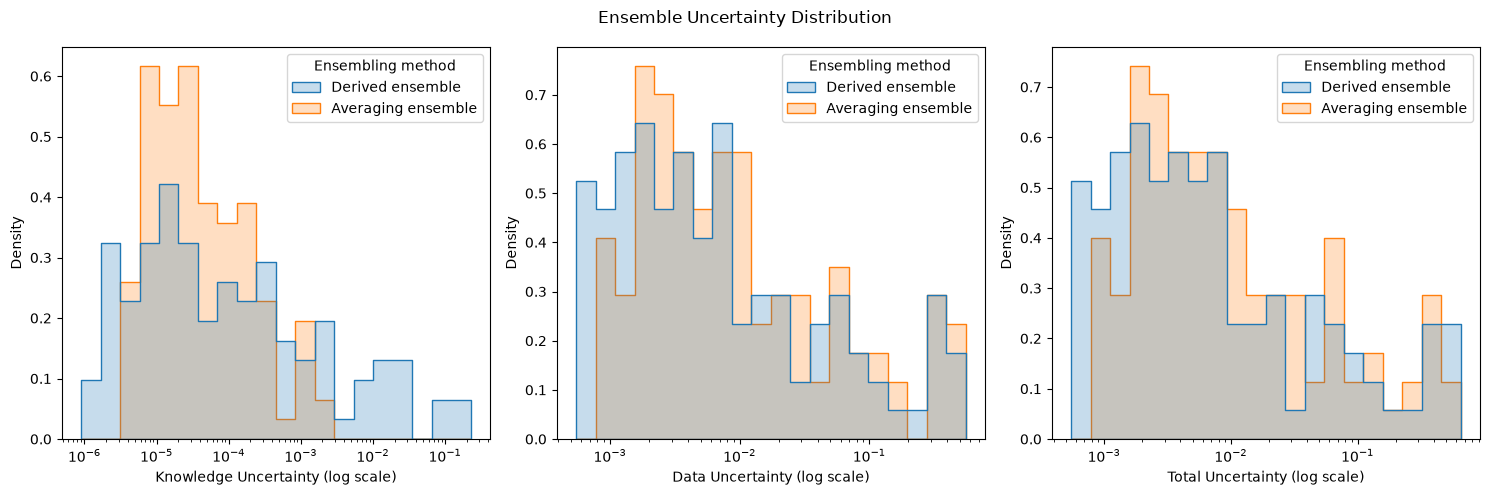

In [13]:
uncertainty_types = ["knowledge_uncertainty", "data_uncertainty", "total_uncertainty"]
ensemble_uncertainties = pd.concat(
    {
        "Derived ensemble": ensemble_prediction_derived[uncertainty_types],
        "Averaging ensemble": ensemble_prediction_averaging[uncertainty_types],
    },
    names=["Ensembling method"],
).reset_index(level="Ensembling method")

fig, axs = plt.subplots(1, 3, figsize=(15, 5))

for uncertainty_type in uncertainty_types:
    ax = axs[uncertainty_types.index(uncertainty_type)]
    sns.histplot(
        ax=ax,
        data=ensemble_uncertainties,
        x=uncertainty_type,
        hue="Ensembling method",
        bins=20,
        stat="density",
        common_norm=False,
        element="step",
        fill=True,
        log_scale=(True, False),
    )
    ax.set_xlabel(f"{uncertainty_type.replace('_', ' ').title()} (log scale)")
    ax.set_ylabel("Density")

fig.suptitle("Ensemble Uncertainty Distribution")
plt.tight_layout()
plt.show()

> As uncertainty estimation uses different strategies, distributions do not fully overlap between ensemble classes.